# Treatment-associated changes in effective connectivity

We summarize longitudinal effective connectivity among nine retained independent components using the final DCM and PEB exports. The three-visit PEB sample includes 44 participants, with 22 in each treatment arm. The original and motion-adjusted models share eight selected directed connections; the motion-adjusted model identifies six additional candidates, retained in the supplementary tables.

The main figures show the observed trajectories of the two focal connections and the anatomy and treatment-change contrasts of all eight shared connections. The supplementary figures show the complete five-specification comparison and all shared observed trajectories. The focal connections were identified through the completed treatment-sensitivity comparisons; they were not selected using clinical-outcome associations.

Observed trajectories summarize individual DCM estimates with one standard error. Treatment contrasts use full-PEB means and their pointwise 95% credible intervals. BMA selection support is reported separately. Component colors identify the source and target of a modeled connection and do not represent anatomical tracts or effect signs. Clinical correspondence is examined separately in Section 4.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd

# project PATH
DATASET_NAME = "sz_meditation"
project_path_str="/scratch/repo_"+DATASET_NAME
project_path= Path(project_path_str)
sys.path.append(str(project_path))

# importing private libs and functions (imaging_arsenal version, need to import the parent dir as well)
private_lib_path = Path('/scratch/imaging_arsenal')
sys.path.append(str(private_lib_path))
sys.path.append(str(private_lib_path / 'utils_'))
print('private lib ready:',(private_lib_path / 'utils_private.py').exists())
from utils_.utils_private import report_cpu, report_unified_missingness
report_cpu()

# data path
data_path = project_path / 'data' 
peb_path = data_path / 'dcm' / 'PEB_section3'
fig_path = project_path / 'fig' 
ICs_file = Path('/scratch/sz_meditation/derivatives/results_20260701/canICA_038_noGSR') / 'method-canICA_ses-038_task-rs_desc-noGSR_ICmaps.nii.gz'

# data
basic_time_Tag = "20240724"
all_DKT_path = data_path / (DATASET_NAME+'_R_'+basic_time_Tag+'.csv')

# read data
all_df = pd.read_csv(all_DKT_path, index_col= None)

private lib ready: False


/opt/conda/lib/python3.9/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


Total CPUs: 12
Total Memory: 29.38 GB
Available Memory: 21.64 GB


In [2]:
# report major software version
import statsmodels 
import nilearn
import sys
import sklearn
import semopy
import seaborn as sns
import networkx as nx
# setup random seed
rand_seed = 24
np.random.seed(rand_seed)

print('python version:', sys.version)
print('numpy version:', np.__version__)
print('statsmodels version:', statsmodels.__version__)
print('nilearn version:', nilearn.__version__)
print('sklearn version:', sklearn.__version__)
print('semopy version:', semopy.__version__)
print('networkX version:', nx.__version__)
print('seaborn version:', sns.__version__)
print('random seed:', rand_seed)

python version: 3.9.12 | packaged by conda-forge | (main, Mar 24 2022, 23:25:59) 
[GCC 10.3.0]
numpy version: 1.26.4
statsmodels version: 0.14.5
nilearn version: 0.12.0
sklearn version: 1.4.2
semopy version: 2.3.11
networkX version: 3.1
seaborn version: 0.13.2
random seed: 24


## 1. Load paths and the agreed names for Section 3 EC reporting.

In [3]:
# Set the paper palette, names and plotting style; keep the existing input paths.
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import FancyArrowPatch
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.ticker import MaxNLocator
import seaborn as sns
from IPython.display import display

save_figs = 1
save_each_edge = 1
save_tables = 1
DPI_VAL = 300

ec_colors = {'control': '#7fbc41', 'meditation': '#4393c3'}
ec_outlines = {'control': '#276419', 'meditation': '#2166ac'}
ec_markers = {'control': 's', 'meditation': 'o'}
month_colors = {3: '#E69F00', 8: '#005AB5'}
month_markers = {3: 's', 8: 'o'}
brain_cmaps = {'source': plt.get_cmap('RdBu_r'),
               'target': plt.get_cmap('PuOr_r')}
LINE_WIDTH, ERROR_WIDTH, MARKER_SIZE, MARKEREDGEWIDTH = 4.0, 2.2, 12, 3.5
visits = [0, 3, 8]

preferred_order = [
    ('IC02_SalVentA', 'IC00_SMN'),
    ('IC02_SalVentA', 'IC04_Vis_V1'),
    ('IC02_SalVentA', 'IC18_SalVentB'),
    ('IC04_Vis_V1', 'IC00_SMN'),
    ('IC04_Vis_V1', 'IC09_pDMN'),
    ('IC15_DAN', 'IC05_aDMN'),
    ('IC18_SalVentB', 'IC05_aDMN'),
    ('IC19_ECN', 'IC05_aDMN'),
]
focal_edges = [preferred_order[0], preferred_order[2]]
node_names = {
    'IC00_SMN': 'SMN', 'IC02_SalVentA': 'SMG–VAN',
    'IC04_Vis_V1': 'mVIS', 'IC05_aDMN': 'mPFC–DMN',
    'IC09_pDMN': 'PCu–DMN', 'IC15_DAN': 'SPL–DAN',
    'IC16_FPCN': 'rIPL–FPN', 'IC18_SalVentB': 'MFG–VAN/FPN',
    'IC19_ECN': 'lIFG–FPN',
}
node_labels = node_names
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 12,
    'axes.labelsize': 13, 'axes.titlesize': 13,
    'xtick.labelsize': 11, 'ytick.labelsize': 11,
    'axes.linewidth': 1.2, 'pdf.fonttype': 42, 'svg.fonttype': 'none',
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'text.color': 'black', 'axes.labelcolor': 'black',
    'xtick.color': 'black', 'ytick.color': 'black',
})

def node_name(node):
    return f'{node.split("_")[0]} {node_names[node]}'

def edge_name(edge):
    return f'{node_name(edge[0])} → {node_name(edge[1])}'

def save_figure(fig, name):
    if save_figs:
        fig_path.mkdir(parents=True, exist_ok=True)
        for extension in ['pdf', 'png']:
            fig.savefig(fig_path / f'{name}.{extension}', dpi=DPI_VAL,
                        facecolor='white', bbox_inches='tight')

def saved_flag(values):
    return values.astype(str).str.strip().str.lower().isin(['1', '1.0', 'true'])

## 2a. Load the final discovery data, selection and full-PEB tables.

In [4]:
# 2a. Load the final discovery data, selection and full-PEB tables.
# Use only the merged MATLAB exports; no clinical-class merge or model refitting.
edge_dictionary = pd.read_csv(peb_path / 'Selected_edge_dictionary.csv')
ec_data = pd.read_csv(peb_path / 'DCM_selected_edges_all_available.csv')
coefficients = pd.read_csv(peb_path / 'PEB_treatment_coefficients.csv')
contrasts = pd.read_csv(peb_path / 'PEB_contrasts.csv')

In [5]:
discovery = ec_data.loc[saved_flag(ec_data['In_PEB_Discovery'])].copy()
discovery['Group'] = discovery['Group'].str.strip().str.lower()
edge_columns = edge_dictionary.set_index(['Source_Node', 'Target_Node'])['CSV_Column'].to_dict()
shared = edge_dictionary.loc[saved_flag(edge_dictionary['Selected_both'])]
shared_edges = list(shared[['Source_Node', 'Target_Node']].itertuples(index=False, name=None))
edge_order = [edge for edge in preferred_order if edge in shared_edges]
edge_order += [edge for edge in shared_edges if edge not in edge_order]
N_discovery = discovery['Participant_ID'].nunique()
arm_counts = discovery.groupby('Group')['Participant_ID'].nunique()
n_nofd = int(saved_flag(edge_dictionary['Selected_No_FD']).sum())
n_fd = int(saved_flag(edge_dictionary['Selected_FD_adjusted']).sum())
n_additional = int((saved_flag(edge_dictionary['Selected_FD_adjusted'])
                   & ~saved_flag(edge_dictionary['Selected_both'])).sum())
changes = contrasts.loc[contrasts['Contrast'].eq('Group_difference_in_change')].copy()
fitted_means = contrasts.loc[contrasts['Contrast'].eq('Fitted_group_mean')].copy()
display(discovery.groupby(['Group', 'Session_Month'])['Participant_ID'].nunique().rename('N').to_frame())
display(changes[['Model', 'End_month', 'N', 'Control_N', 'Meditation_N']].drop_duplicates())
print(f'No-FD selection: {n_nofd}; FD selection: {n_fd}; shared: {len(edge_order)}.')

N
Group      Session_Month    
control    0              22
           3              22
           8              22
meditation 0              22
           3              22
           8              22

,Model,End_month,N,Control_N,Meditation_N
0,No_FD,3,44,22,22
72,FD_adjusted,3,44,22,22
144,Three_visit_windowFD,3,44,22,22
216,Paired_complete,3,44,22,22
288,Paired_all_eligible,3,53,25,28
360,No_FD,8,44,22,22
432,FD_adjusted,8,44,22,22
504,Three_visit_windowFD,8,44,22,22
576,Paired_complete,8,44,22,22
648,Paired_all_eligible,8,46,22,24


No-FD selection: 8; FD selection: 14; shared: 8.


## 2b. Arrange the saved contrasts for plotting and display the selection terms.


In [ ]:
# 2b. Arrange the saved contrasts for plotting and display the selection terms.
model_prefixes = {
    'No_FD': 'NoFD_3visit', 'FD_adjusted': 'FD_3visit',
    'Three_visit_windowFD': 'WindowFD_3visit',
    'Paired_complete': 'Paired44', 'Paired_all_eligible': 'All_pairs',
}
change_index = changes.set_index(['Source_Node', 'Target_Node', 'End_month', 'Model'])
report_rows = []
for _, edge in edge_dictionary.iterrows():
    terms = coefficients.loc[coefficients['A_Linear_Index'].eq(edge['A_Linear_Index'])]
    selected_terms = terms.loc[terms['BMA_Pp'].gt(terms['Pp_threshold'])]
    nofd_terms = '; '.join(selected_terms.loc[selected_terms['Model'].eq('No_FD'), 'Term'])
    fd_terms = '; '.join(selected_terms.loc[selected_terms['Model'].eq('FD_adjusted'), 'Term'])
    for month in [3, 8]:
        row = {'Source_Node': edge['Source_Node'], 'Target_Node': edge['Target_Node'],
               'A_Linear_Index': edge['A_Linear_Index'], 'End_month': month,
               'NoFD_selected_terms': nofd_terms, 'FD_selected_terms': fd_terms}
        for model_name, prefix in model_prefixes.items():
            saved = change_index.loc[(edge['Source_Node'], edge['Target_Node'], month, model_name)]
            for output, source in [('N', 'N'), ('mean_Hz', 'FullPEB_mean_Hz'),
                                   ('low_Hz', 'FullPEB_CrI95_low_Hz'),
                                   ('high_Hz', 'FullPEB_CrI95_high_Hz')]:
                row[f'{prefix}_{output}'] = saved[source]
        report_rows.append(row)
evidence = pd.DataFrame(report_rows).set_index(['Source_Node', 'Target_Node', 'End_month'])
selection_rows = []
for edge in edge_order:
    row = evidence.loc[(*edge, 3)]
    selection_rows.append({'Edge': edge_name(edge), 'No_FD_term': row['NoFD_selected_terms'],
                          'FD_term': row['FD_selected_terms']})
display(pd.DataFrame(selection_rows))
print('Observed trajectories use individual DCM means; treatment intervals use full-PEB contrasts.')
print('The two focal edges reflect the completed sensitivity review, not clinical-association selection.')

,Edge,No_FD_term,FD_term
0,IC02 SMG–VAN → IC00 SMN,Group_x_Quadratic,Group_x_Quadratic
1,IC02 SMG–VAN → IC04 mVIS,Group_x_Linear,Group_x_Linear
2,IC02 SMG–VAN → IC18 MFG–VAN/FPN,Group_x_Quadratic,Group_x_Quadratic
3,IC04 mVIS → IC00 SMN,Group_x_Quadratic,Group_x_Quadratic
4,IC04 mVIS → IC09 PCu–DMN,Group_x_Quadratic,Group_x_Quadratic
5,IC15 SPL–DAN → IC05 mPFC–DMN,Group_x_Quadratic,Group_x_Quadratic
6,IC18 MFG–VAN/FPN → IC05 mPFC–DMN,Group_x_Linear,Group_x_Linear
7,IC19 lIFG–FPN → IC05 mPFC–DMN,Group_x_Linear,Group_x_Linear


Observed trajectories use individual DCM means; treatment intervals use full-PEB contrasts.
The two focal edges reflect the completed sensitivity review, not clinical-association selection.


## 3. Plot the two focal observed trajectories for Figure 3.


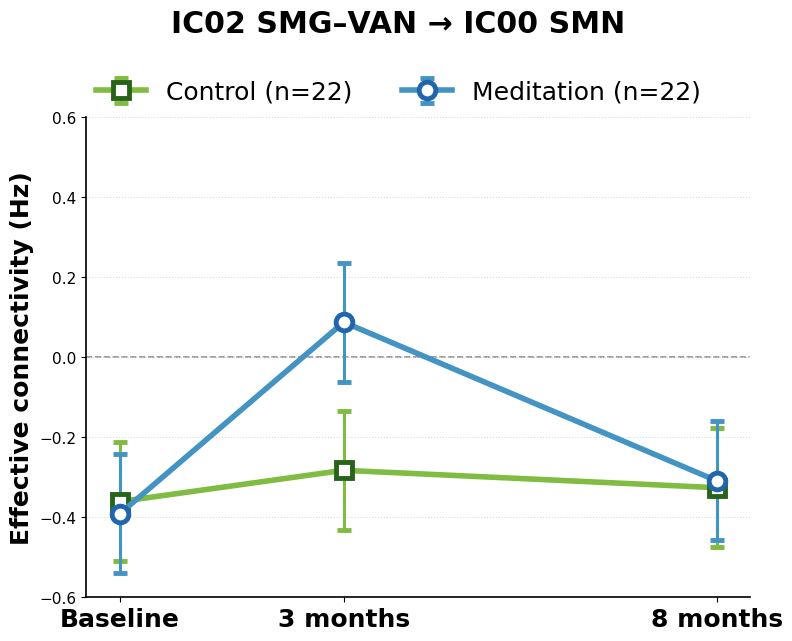

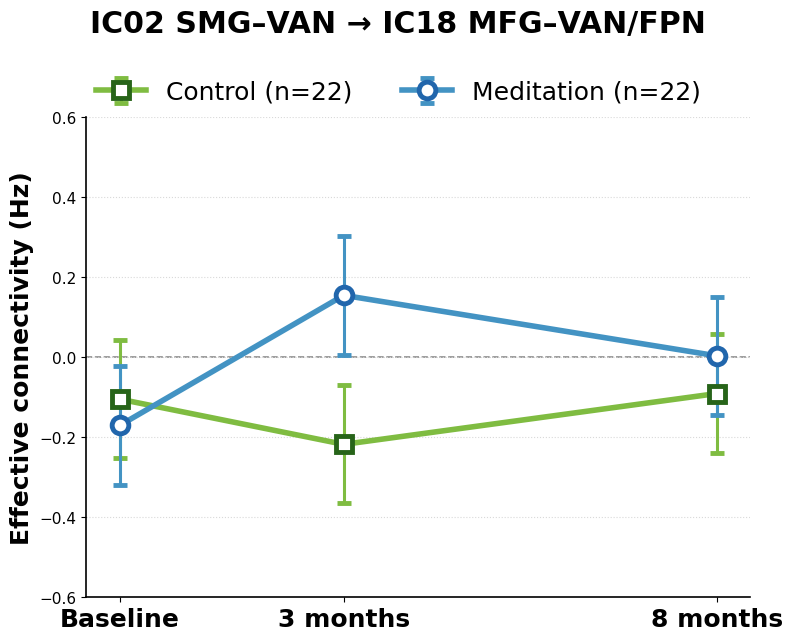

In [ ]:
# Plot saved FD-adjusted full-PEB means and 95% CrIs; make two separate PPT figures.
LABEL_SIZE = 18

def fitted_rows(edge, group):
    return fitted_means.loc[
        fitted_means['Model'].eq('FD_adjusted')
        & fitted_means['Source_Node'].eq(edge[0])
        & fitted_means['Target_Node'].eq(edge[1])
        & fitted_means['Group'].eq(group)
    ].sort_values('End_month')

def effect_values(edge, month, prefix='FD_3visit'):
    row = evidence.loc[(*edge, month)]
    return tuple(float(row[f'{prefix}_{field}_Hz'])
                 for field in ['mean', 'low', 'high'])

def effect_text(edge, month):
    mean, low, high = effect_values(edge, month)
    return f'0–{month} months: {mean:+.3f} Hz [{low:+.3f}, {high:+.3f}]'

def fitted_ylim(edges):
    bounds = []
    for edge in edges:
        for group in ec_colors:
            part = fitted_rows(edge, group)
            bounds.extend(part['FullPEB_CrI95_low_Hz'])
            bounds.extend(part['FullPEB_CrI95_high_Hz'])
    low, high = min(0, min(bounds)), max(0, max(bounds))
    pad = 0.08 * (high - low)
    return low - pad, high + pad

def plot_trajectory(ax, edge, title=True):
    for group, color in ec_colors.items():
        part = fitted_rows(edge, group)
        mean = part['FullPEB_mean_Hz'].to_numpy()
        error = np.vstack([mean - part['FullPEB_CrI95_low_Hz'].to_numpy(),
                           part['FullPEB_CrI95_high_Hz'].to_numpy() - mean])
        ax.errorbar(part['End_month'], mean, yerr=error, color=color,
                    marker=ec_markers[group], linewidth=LINE_WIDTH,
                    elinewidth=ERROR_WIDTH, markersize=MARKER_SIZE,
                    markerfacecolor='white', markeredgecolor=ec_outlines[group], markeredgewidth=MARKEREDGEWIDTH,
                    capsize=5, capthick=ERROR_WIDTH,
                    label=f'{group.capitalize()} (n={arm_counts[group]})')
    if title:
        ax.set_title(edge_name(edge), fontweight='bold', fontsize=13, pad=14)
    ax.set_xticks(visits)
    ax.set_xticklabels(['Baseline', '3 months', '8 months'], fontweight='bold', fontsize=LABEL_SIZE)
    ax.set_xlim(-0.45, 8.45)
    ax.set_ylabel('Effective connectivity (Hz)', fontsize=LABEL_SIZE, fontweight='bold')
    ax.set_ylim(fitted_ylim([edge]))
    ax.axhline(0, color='0.55', linestyle='--', linewidth=1.2, zorder=0)
    ax.grid(axis='y', linestyle=':', color='0.85', linewidth=0.8)
    sns.despine(ax=ax)

focal_ylim = fitted_ylim(focal_edges)
focal_ylim = [-0.6, 0.6]
for edge in focal_edges:
    fig, ax = plt.subplots(figsize=(8, 8), facecolor='white')
    plot_trajectory(ax, edge, title=False)
    ax.set_ylim(focal_ylim)
    fig.suptitle(edge_name(edge), fontsize=LABEL_SIZE*1.2, fontweight='bold', x=0.54, y=0.985)
    handles, labels = ax.get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.54, 0.925),
               ncol=2, frameon=False, fontsize=LABEL_SIZE)
    #fig.text(0.5, 0.110, 'Meditation − control difference in change (95% CrI)',
    #         ha='center', fontsize=10)
    #for month, y in [(3, 0.071), (8, 0.029)]:
    #    fig.text(0.5, y, effect_text(edge, month), ha='center',
    #             color=month_colors[month], fontsize=11, fontweight='bold')
    fig.subplots_adjust(left=0.15, right=0.98, bottom=0.25, top=0.85)
    save_figure(fig, f'Fig3b_{edge[0][:4]}_to_{edge[1][:4]}_FD_trajectory')
    plt.show()

## 4. Prepare the component supports for the glass brains.


In [8]:
# Retain signed IC loadings at the current display threshold; define source/target glass brains.
import nibabel as nib
from nilearn import image, plotting

ICA_img = nib.load(ICs_file)
DISPLAY_PERCENTILE = 25  # Retain the upper 75% of absolute nonzero loadings.
component_maps, component_limits = {}, []

for node in node_names:
    ref = image.index_img(ICA_img, int(node[2:4]))
    values = ref.get_fdata()
    absolute = np.abs(values)
    nonzero = absolute[np.isfinite(absolute) & (absolute > 0)]
    cutoff = np.percentile(nonzero, DISPLAY_PERCENTILE)
    support = np.isfinite(values) & (absolute > 0) & (absolute >= cutoff)
    component_maps[node] = image.new_img_like(ref, np.where(support, values, 0.0))
    component_limits.append(nonzero.max())
brain_vmax = max(component_limits)
brain_norm = Normalize(vmin=-brain_vmax, vmax=brain_vmax)

def draw_component(fig, rect, node, role):
    return plotting.plot_glass_brain(
        component_maps[node], figure=fig, axes=rect, display_mode='lzr',
        colorbar=False, black_bg=False, annotate=True, alpha=0.45,
        cmap=brain_cmaps[role], plot_abs=False, symmetric_cbar=True,
        vmin=-brain_vmax, vmax=brain_vmax, threshold=np.finfo(float).tiny,
        resampling_interpolation='nearest')

def add_brain_keys(fig, y=0.035, width=0.23, fontsize=10):
    for role, left in [('source', 0.20), ('target', 0.60)]:
        cax = fig.add_axes([left, y, width, 0.011])
        cb = fig.colorbar(ScalarMappable(norm=brain_norm, cmap=brain_cmaps[role]),
                          cax=cax, orientation='horizontal',
                          ticks=[-brain_vmax, 0, brain_vmax])
        cb.ax.set_xticklabels([f'{-brain_vmax:.3g}', '0', f'{brain_vmax:.3g}'])
        cb.ax.tick_params(labelsize=fontsize, length=2)
        cb.outline.set_linewidth(0.5)
        cax.set_title(f'{role.capitalize()}: signed IC loading', fontsize=fontsize, pad=6)

def draw_edge_brains(fig, rect, edge, labelsize=10):
    x, y, width, height = rect
    displays = []
    for node, role, offset in [(edge[0], 'source', 0), (edge[1], 'target', 0.54)]:
        displays.append(draw_component(
            fig, [x + offset*width, y + 0.14*height, 0.46*width, 0.86*height], node, role))
        fig.text(x + (offset + 0.23)*width, y + 0.02*height, role.capitalize(),
                 ha='center', va='bottom', fontsize=labelsize, color='0.25')
    fig.add_artist(FancyArrowPatch(
        (x + 0.465*width, y + 0.57*height), (x + 0.535*width, y + 0.57*height),
        transform=fig.transFigure, arrowstyle='-|>', mutation_scale=15,
        linewidth=1.8, color='0.25'))
    return displays

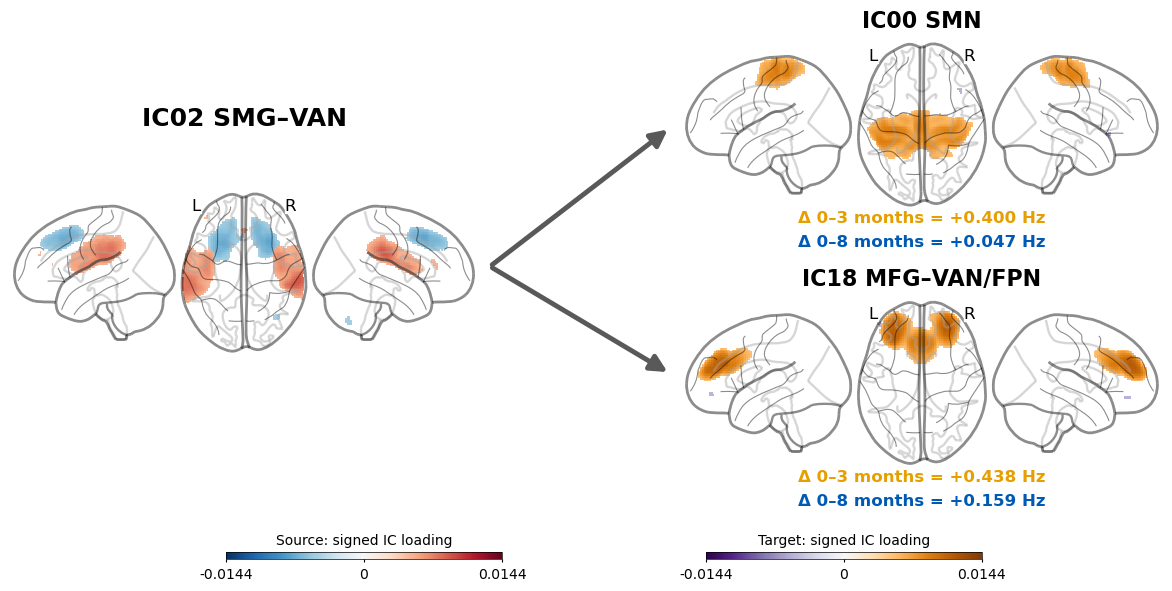

In [9]:
# Arrange the shared IC02 source and two targets for Fig3b; export separate anatomy assets for PPT.
fig_anatomy = plt.figure(figsize=(12, 6.3), facecolor='white')
source = focal_edges[0][0]
anatomy_displays = [draw_component(fig_anatomy, [0.02, 0.31, 0.39, 0.38], source, 'source')]
fig_anatomy.text(0.215, 0.735, node_name(source), ha='center', fontsize=18, fontweight='bold')
for edge, bottom, arrow_end in [(focal_edges[0], 0.60, 0.73),
                                 (focal_edges[1], 0.19, 0.34)]:
    anatomy_displays.append(draw_component(fig_anatomy, [0.58, bottom, 0.40, 0.27], edge[1], 'target'))
    fig_anatomy.text(0.78, bottom + 0.29, node_name(edge[1]), ha='center',
                     fontsize=16, fontweight='bold')
    fig_anatomy.add_artist(FancyArrowPatch(
        (0.42, 0.51), (0.57, arrow_end), transform=fig_anatomy.transFigure,
        arrowstyle='-|>', mutation_scale=25, linewidth=3.5, color='0.35'))
    for month, offset in [(3, -0.020), (8, -0.058)]:
        mean = effect_values(edge, month)[0]
        fig_anatomy.text(0.78, bottom + offset, f'Δ 0–{month} months = {mean:+.3f} Hz',
                         ha='center', fontsize=12, fontweight='bold', color=month_colors[month])
add_brain_keys(fig_anatomy, y=0.045, fontsize=10)
save_figure(fig_anatomy, 'Fig3b_IC02_source_and_targets')
plt.show()

if save_figs:
    for node, role in [(source, 'source')] + [(edge[1], 'target') for edge in focal_edges]:
        fig = plt.figure(figsize=(6.5, 2.7), facecolor='white')
        draw_component(fig, [0.02, 0.06, 0.96, 0.76], node, role)
        fig.text(0.5, 0.88, node_name(node), ha='center', fontsize=17, fontweight='bold')
        save_figure(fig, f'Fig3b_{node[:4]}_{role}_glassbrain')
        plt.close(fig)

### 4.2 Output source and target IC maps

In [22]:
# Prepare adjustable signed maps and contour supports; keep current in-notebook section 4 unchanged.
from matplotlib.ticker import FormatStrFormatter

PPT_PERCENTILE = 20  # 25 retains the upper 75%; 75 retains the upper 25%.
EC_PERCENTILE = 20   # Display threshold for the combined EC panels.

PPT_VIEWS, EC_VIEWS = 'lzr', 'lyrz'
PPT_TITLE, PPT_COLORBAR = False, False
SAVE_PPT_MAPS, SAVE_EC_PANELS = 1, 1
SHOW_PPT_MAPS = True
CONTOUR_WIDTH = 0.9
CONTROUR_TRANS = 0.8
EC_BRAIN_FRACTION = 0.60  # More brain space leaves less space for the effects.
EC_PANEL_GAP = 0.10

overlay_opacity = {'source': 0.90, 'target': 0.70}
contour_styles = {'source': '-', 'target': '--'}
ppt_dir = fig_path / 'Section3_PPT'

def prepare_presentation_maps(percentile):
    maps = {}
    for node in node_names:
        original = image.index_img(ICA_img, int(node[2:4]))
        values = original.get_fdata()
        absolute = np.abs(values)
        nonzero = absolute[np.isfinite(absolute) & (absolute > 0)]
        cutoff = np.percentile(nonzero, percentile)
        keep = np.isfinite(values) & (absolute > 0) & (absolute >= cutoff)
        maps[node] = {
            'image': image.new_img_like(original, np.where(keep, values, 0.0)),
            'support': image.new_img_like(original, keep.astype(float)),
            'threshold': float(absolute[keep].min() / 2),
        }
    return maps

# Start from the original maps, so lowering the threshold can restore displayed voxels.
ppt_maps = prepare_presentation_maps(PPT_PERCENTILE)
ec_panel_maps = prepare_presentation_maps(EC_PERCENTILE)

def add_map_contour(brain, maps, node, role):
    brain.add_contours(maps[node]['support'], threshold=None, levels=[0.5],
                       colors=['0.20'], linewidths=CONTOUR_WIDTH,
                       linestyles=contour_styles[role], transparency=CONTROUR_TRANS,
                       resampling_interpolation='nearest')

def draw_signed_overlay(fig, rect, nodes_and_roles, maps, views, transparent=False):
    frame_ax = fig.add_axes(rect, facecolor='none' if transparent else 'white')
    brain = plotting.plot_glass_brain(
        None, figure=fig, axes=frame_ax, display_mode=views, colorbar=False,
        plot_abs=False, annotate=True, black_bg=False, alpha=0.45)
    for node, role in nodes_and_roles:
        opacity = 1.0 if len(nodes_and_roles) == 1 else overlay_opacity[role]
        brain.add_overlay(maps[node]['image'], threshold=maps[node]['threshold'],
                          cmap=brain_cmaps[role], vmin=-brain_vmax, vmax=brain_vmax,
                          colorbar=False, transparency=opacity,
                          resampling_interpolation='nearest', interpolation='nearest')
    # Draw both boundaries last, so the second fill cannot hide the first contour.
    for node, role in nodes_and_roles:
        add_map_contour(brain, maps, node, role)
    if transparent:
        frame_ax.patch.set_alpha(0)
        for projection in brain.axes.values():
            projection.ax.patch.set_alpha(0)
    return brain

def draw_ec_overlay(fig, rect, edge):
    return draw_signed_overlay(fig, rect, [(edge[0], 'source'), (edge[1], 'target')],
                               ec_panel_maps, EC_VIEWS)

def add_role_colorbar(fig, rect, role, orientation='vertical', fontsize=11):
    cax = fig.add_axes(rect)
    cb = fig.colorbar(ScalarMappable(norm=brain_norm, cmap=brain_cmaps[role]),
                      cax=cax, orientation=orientation,
                      ticks=[-brain_vmax, 0, brain_vmax])
    axis = cb.ax.yaxis if orientation == 'vertical' else cb.ax.xaxis
    axis.set_major_formatter(FormatStrFormatter('%.3g'))
    cb.ax.tick_params(labelsize=fontsize, length=3)
    cb.set_label('Signed spatial loading', fontsize=fontsize, labelpad=7)
    cb.outline.set_linewidth(0.7)
    return cb

def save_ppt_figure(fig, name, subfolder, transparent=False):
    folder = ppt_dir / subfolder
    folder.mkdir(parents=True, exist_ok=True)
    for extension in ['png', 'pdf']:
        fig.savefig(folder / f'{name}.{extension}', dpi=DPI_VAL,
                    transparent=transparent, facecolor='none' if transparent else 'white',
                    bbox_inches='tight', pad_inches=0.03)

IC00 SMN | source palette | percentile 20


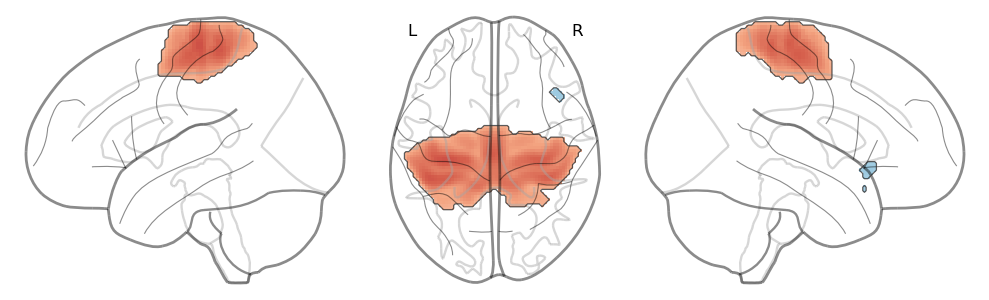

IC00 SMN | target palette | percentile 20


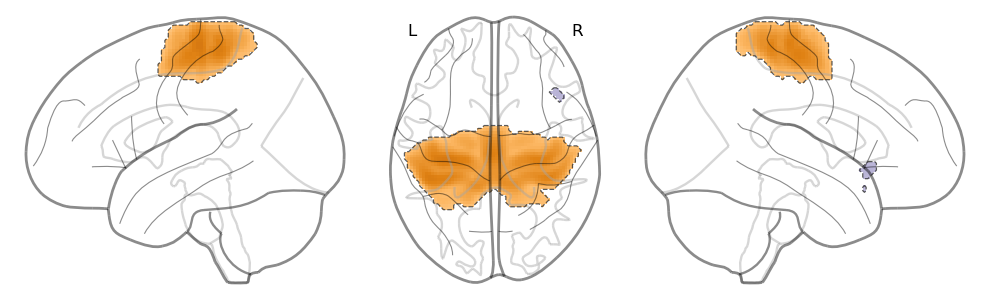

IC02 SMG–VAN | source palette | percentile 20


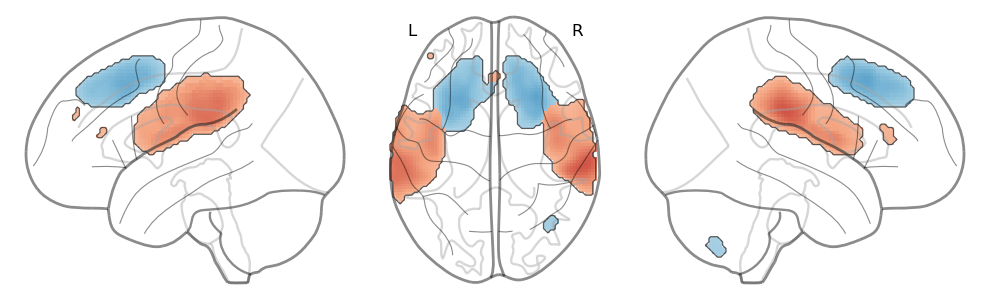

IC02 SMG–VAN | target palette | percentile 20


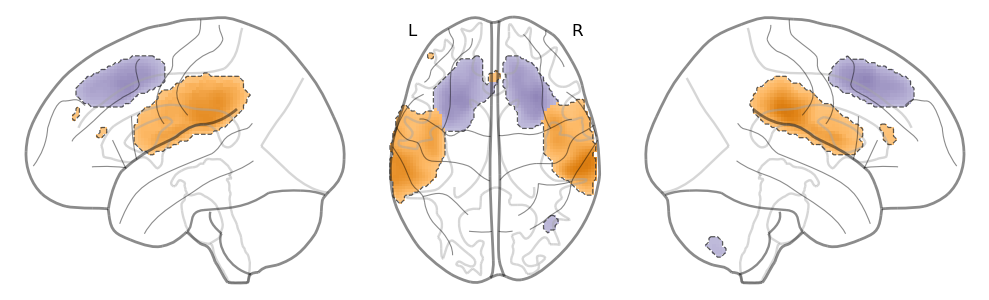

IC04 mVIS | source palette | percentile 20


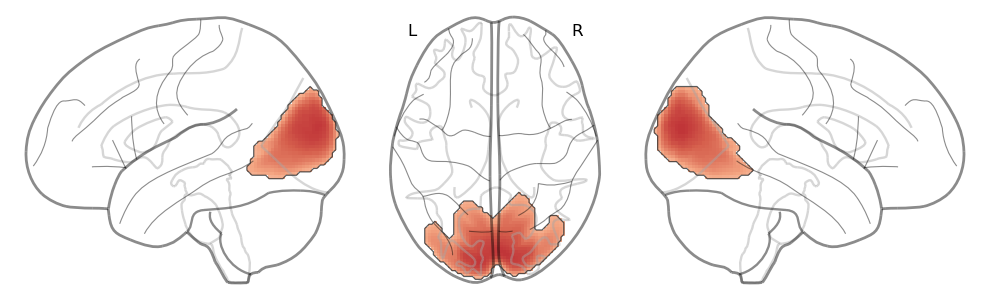

IC04 mVIS | target palette | percentile 20


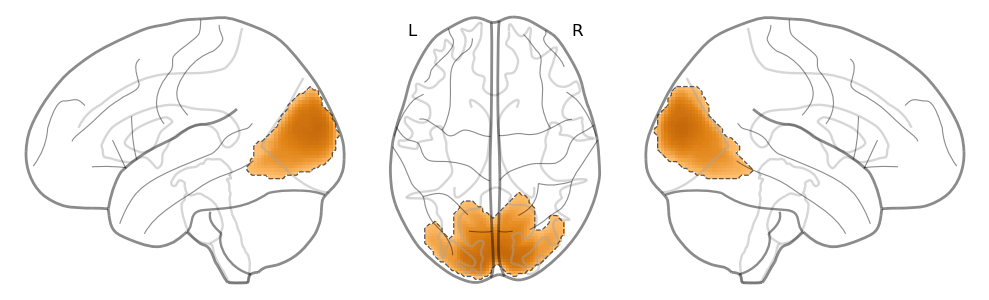

IC05 mPFC–DMN | source palette | percentile 20


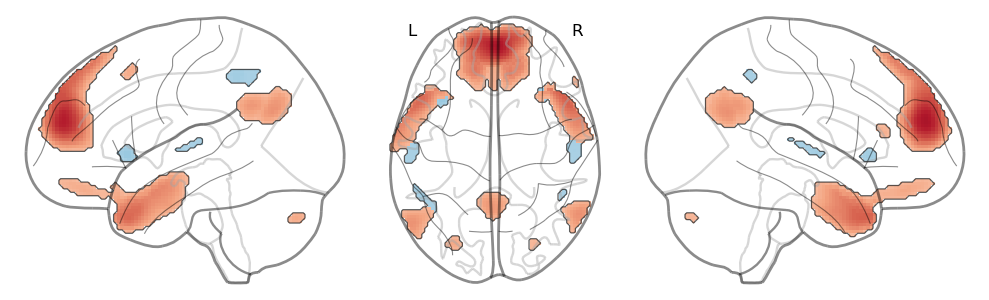

IC05 mPFC–DMN | target palette | percentile 20


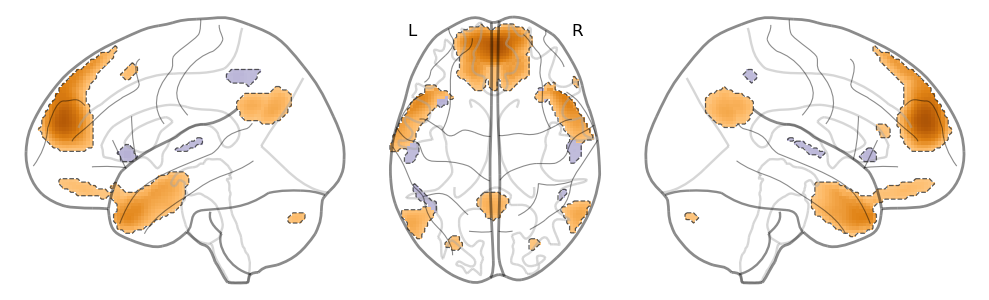

IC09 PCu–DMN | source palette | percentile 20


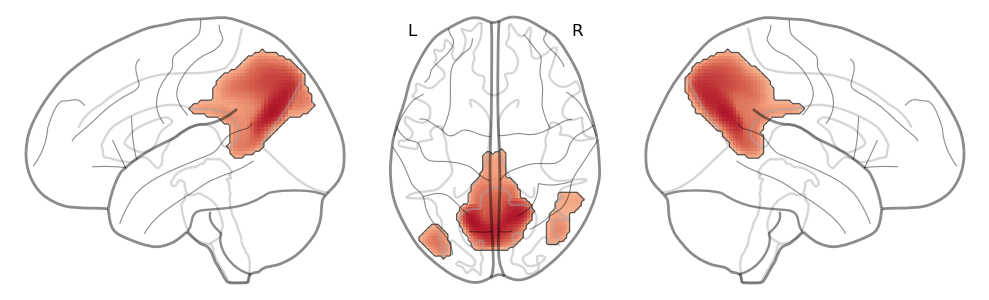

IC09 PCu–DMN | target palette | percentile 20


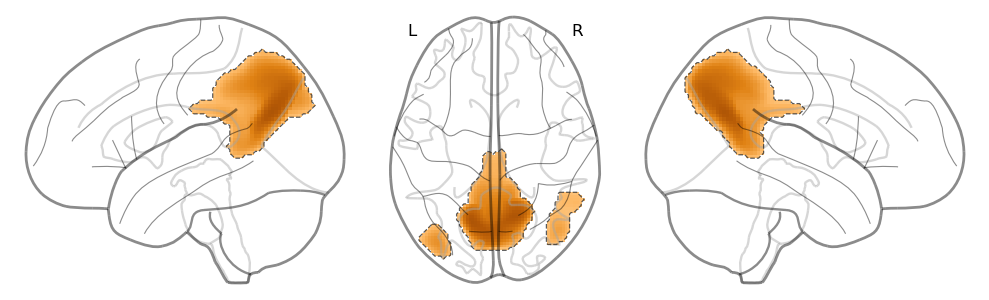

IC15 SPL–DAN | source palette | percentile 20


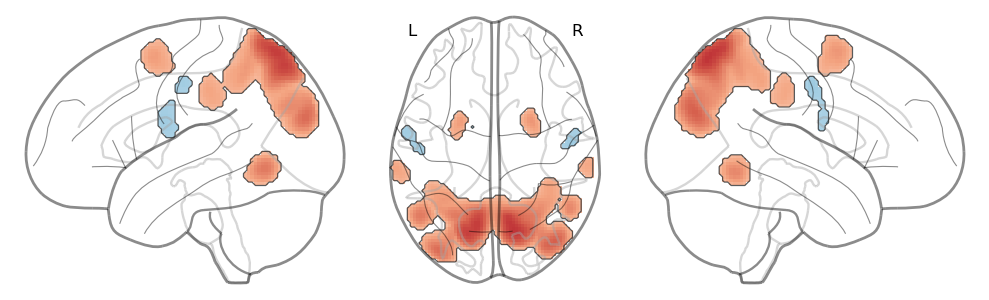

IC15 SPL–DAN | target palette | percentile 20


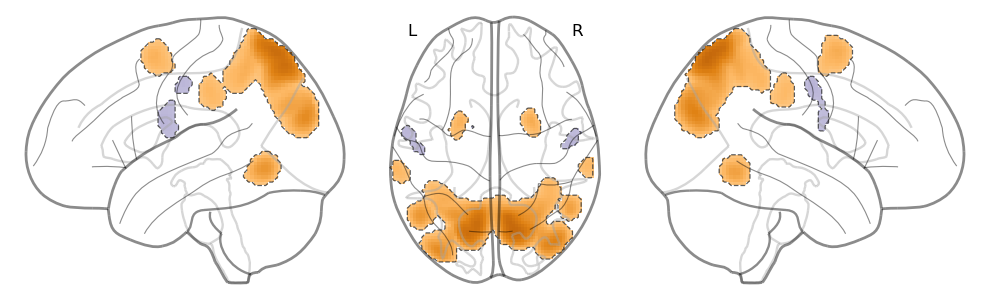

IC16 rIPL–FPN | source palette | percentile 20


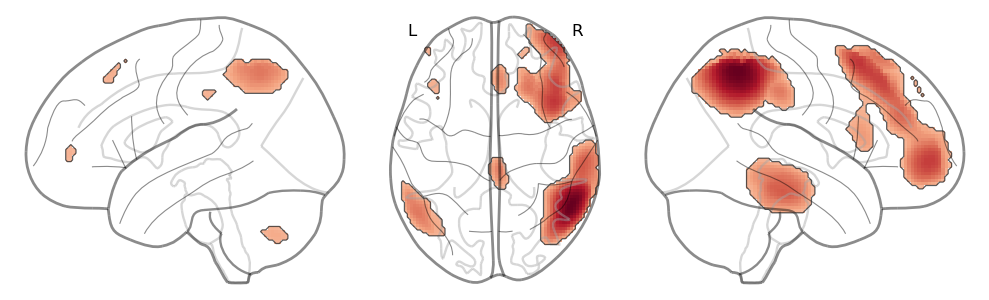

IC16 rIPL–FPN | target palette | percentile 20


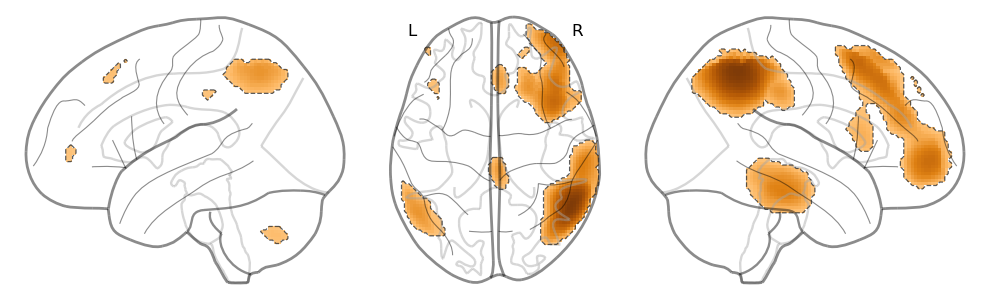

IC18 MFG–VAN/FPN | source palette | percentile 20


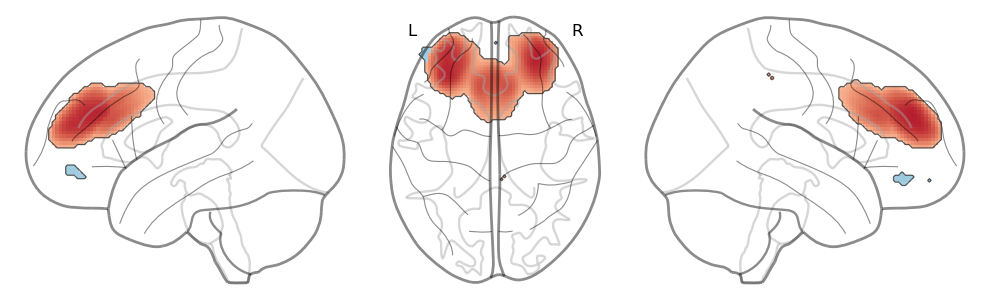

IC18 MFG–VAN/FPN | target palette | percentile 20


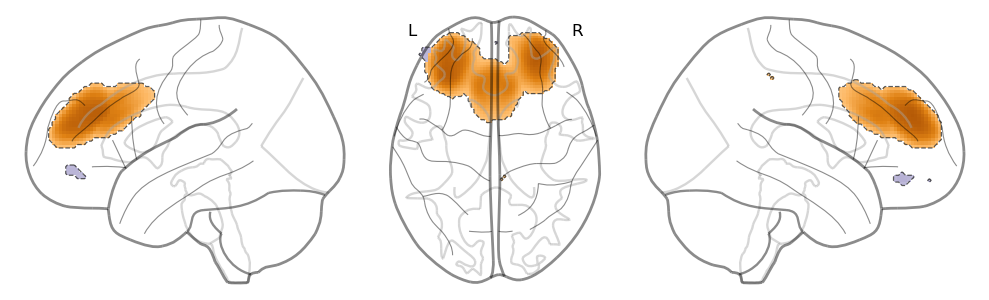

IC19 lIFG–FPN | source palette | percentile 20


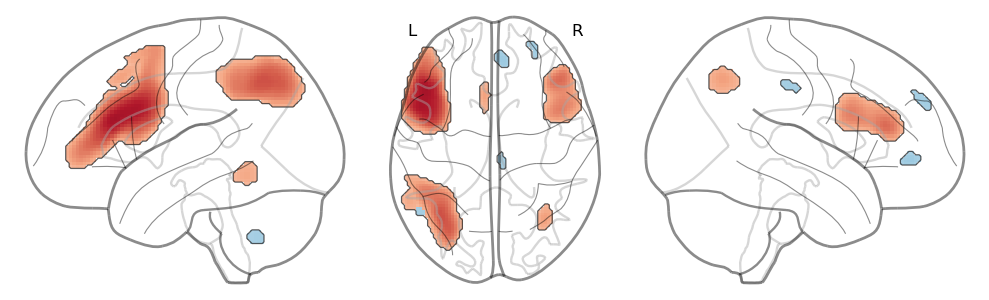

IC19 lIFG–FPN | target palette | percentile 20


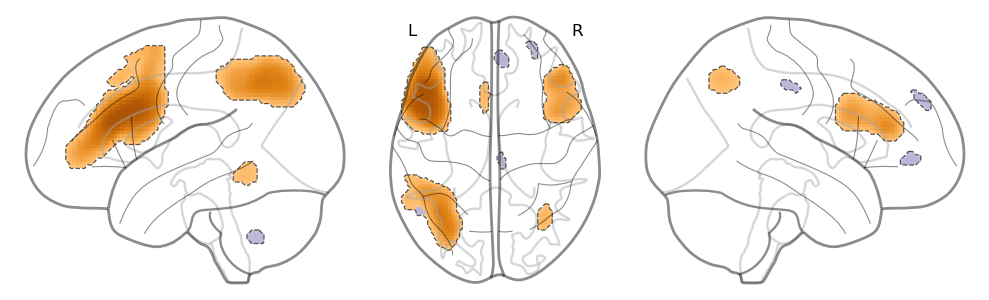

In [23]:
# Export all nine ICs with contours in both palettes; optional colorbars and titles support PPT assembly.
for node in node_names:
    for role in ['source', 'target']:
        fig = plt.figure(figsize=(10, 3.5), facecolor='none')
        rect = [0.015, 0.08, 0.80 if PPT_COLORBAR else 0.97, 0.80]
        brain = draw_signed_overlay(fig, rect, [(node, role)], ppt_maps,
                                     PPT_VIEWS, transparent=True)
        if PPT_TITLE:
            fig.text(0.45, 0.96, node_name(node), ha='center', va='top',
                     fontsize=17, fontweight='bold')
        if PPT_COLORBAR:
            add_role_colorbar(fig, [0.86, 0.20, 0.018, 0.58], role)
        variant = 'with_colorbar' if PPT_COLORBAR else 'plain'
        stem = f'{node[:4]}_{role}_p{PPT_PERCENTILE:g}_{PPT_VIEWS}_{variant}'
        if SAVE_PPT_MAPS:
            save_ppt_figure(fig, stem, 'IC_maps', transparent=True)
        if SHOW_PPT_MAPS:
            print(f'{node_name(node)} | {role} palette | percentile {PPT_PERCENTILE:g}')
            plt.show()
        plt.close(fig)

## vertical colorbar

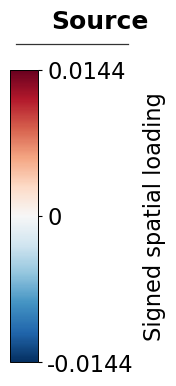

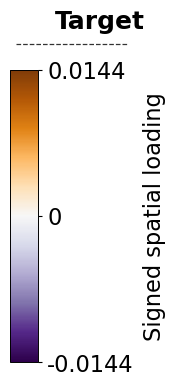

In [36]:
# Export separate source/target color keys with contour styles, for assemblies using maps without colorbars.
for role in ['source', 'target']:
    fig = plt.figure(figsize=(2.8, 4.3), facecolor='none')
    add_role_colorbar(fig, [0.18, 0.12, 0.10, 0.68], role, fontsize=LABEL_SIZE*0.9)

    fig.text(0.5, 0.94, role.capitalize(), ha='center', va='top',
             fontsize=LABEL_SIZE, fontweight='bold')
    
    fig.add_artist(Line2D([0.2, 0.6], [0.86, 0.86], transform=fig.transFigure,
                          color='0.20', linewidth=CONTOUR_WIDTH,
                          linestyle=contour_styles[role]))
    if SAVE_PPT_MAPS:
        save_ppt_figure(fig, f'{role}_signed_loading_colorbar', 'IC_maps', transparent=True)
    plt.show()
    plt.close(fig)

### Horizontal color bar

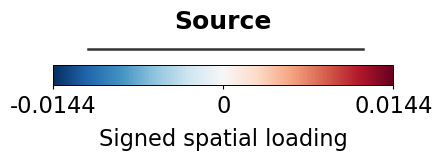

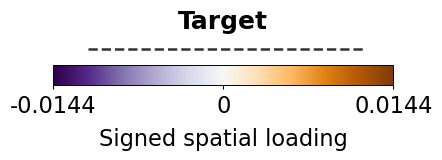

In [56]:
# Export separate source/target color keys with contour styles, for assemblies using maps without colorbars.
for role in ['source', 'target']:
    fig = plt.figure(figsize=(5, 2), facecolor='none')
    add_role_colorbar(fig, [0.18, 0.12,  0.68, 0.10], role, fontsize=LABEL_SIZE*0.9, orientation='horizontal')

    fig.text(0.52, 0.5, role.capitalize(), ha='center', va='top',
             fontsize=LABEL_SIZE, fontweight='bold')
    
    fig.add_artist(Line2D([0.25, 0.8], [0.3, 0.3], transform=fig.transFigure,
                          color='0.20', linewidth=CONTOUR_WIDTH*2,
                          linestyle=contour_styles[role]))
    if SAVE_PPT_MAPS:
        save_ppt_figure(fig, f'{role}_h_signed_loading_colorbar', 'IC_maps', transparent=True)
    plt.show()
    plt.close(fig)

## 5a. Prepare the treatment contrasts and sensitivity display functions.


In [26]:
# Define comparable contrast axes; show both windows together and all five sensitivities without filtering.
specifications = [
    ('NoFD_3visit', 'Three visits; no FD'),
    ('FD_3visit', 'Three visits; FD0/3/8'),
    ('WindowFD_3visit', 'Three visits; window FD'),
    ('Paired44', 'Paired complete cohort'),
    ('All_pairs', 'All available pairs'),
]
extent = max(abs(float(evidence.loc[(*edge, month), f'{prefix}_{bound}_Hz']))
             for edge in edge_order for month in [3, 8]
             for prefix, _ in specifications for bound in ['low', 'high']) * 1.10
contrast_xlim = (-extent, extent)

def plot_primary_contrasts(ax, edge):
    for month, y in [(3, 1), (8, 0)]:
        mean, low, high = effect_values(edge, month)
        ax.errorbar(mean, y, xerr=[[mean-low], [high-mean]],
                    fmt=month_markers[month], color=month_colors[month], markerfacecolor='white',
                    markersize=10, markeredgewidth=1.8, elinewidth=3,
                    capsize=4, capthick=1.8)
        # Center the estimate and 95% CrI directly above its plotted point.
        ax.text(mean, y + 0.27, f'{mean:+.3f} [{low:+.3f}, {high:+.3f}]',
        ha='center', va='bottom', fontsize=13, color=month_colors[month], fontweight='bold')
    ax.axvline(0, color='0.6', linestyle='--', linewidth=1.1, zorder=0)
    ax.set_xlim(contrast_xlim)
    ax.set_ylim(-0.45, 1.65)
    ax.set_yticks([1, 0])
    ax.set_yticklabels(['0–3m', '0–8m'], fontsize=15)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=3))
    ax.tick_params(axis='x', labelsize=12)
    ax.tick_params(axis='y', length=0)
    ax.set_xlabel('Difference in change (Hz)', fontsize=15)
    ax.grid(axis='x', linestyle=':', color='0.87')
    sns.despine(ax=ax, left=True)

def plot_contrast_sensitivity(ax, edge, month):
    row = evidence.loc[(*edge, month)]
    for position, (prefix, label) in enumerate(specifications):
        mean, low, high = effect_values(edge, month, prefix)
        reference = prefix == 'FD_3visit'
        ax.errorbar(mean, position, xerr=[[mean-low], [high-mean]],
                    fmt=month_markers[month], color=month_colors[month],
                    #markerfacecolor=month_colors[month] if reference else 'white',
                    markerfacecolor='white',
                    markeredgewidth=1.6, markersize=7 if reference else 6,
                    elinewidth=3 if reference else 1.8, capsize=3.5, capthick=1.6)
    ax.axvline(0, color='0.6', linestyle='--', linewidth=1.1, zorder=0)
    ax.set_xlim(contrast_xlim)
    ax.set_ylim(4.6, -0.65)
    ax.set_yticks(range(len(specifications)))
    ax.set_yticklabels([f'{label} (n={int(row[prefix + "_N"])})'
                        for prefix, label in specifications], fontsize=12)
    ax.tick_params(axis='y', length=0)
    ax.tick_params(axis='x', labelsize=12)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
    ax.grid(axis='x', linestyle=':', color='0.87')
    sns.despine(ax=ax, left=True)

## 5b. Build Figure 4: eight connections, their anatomy and both treatment-change windows.


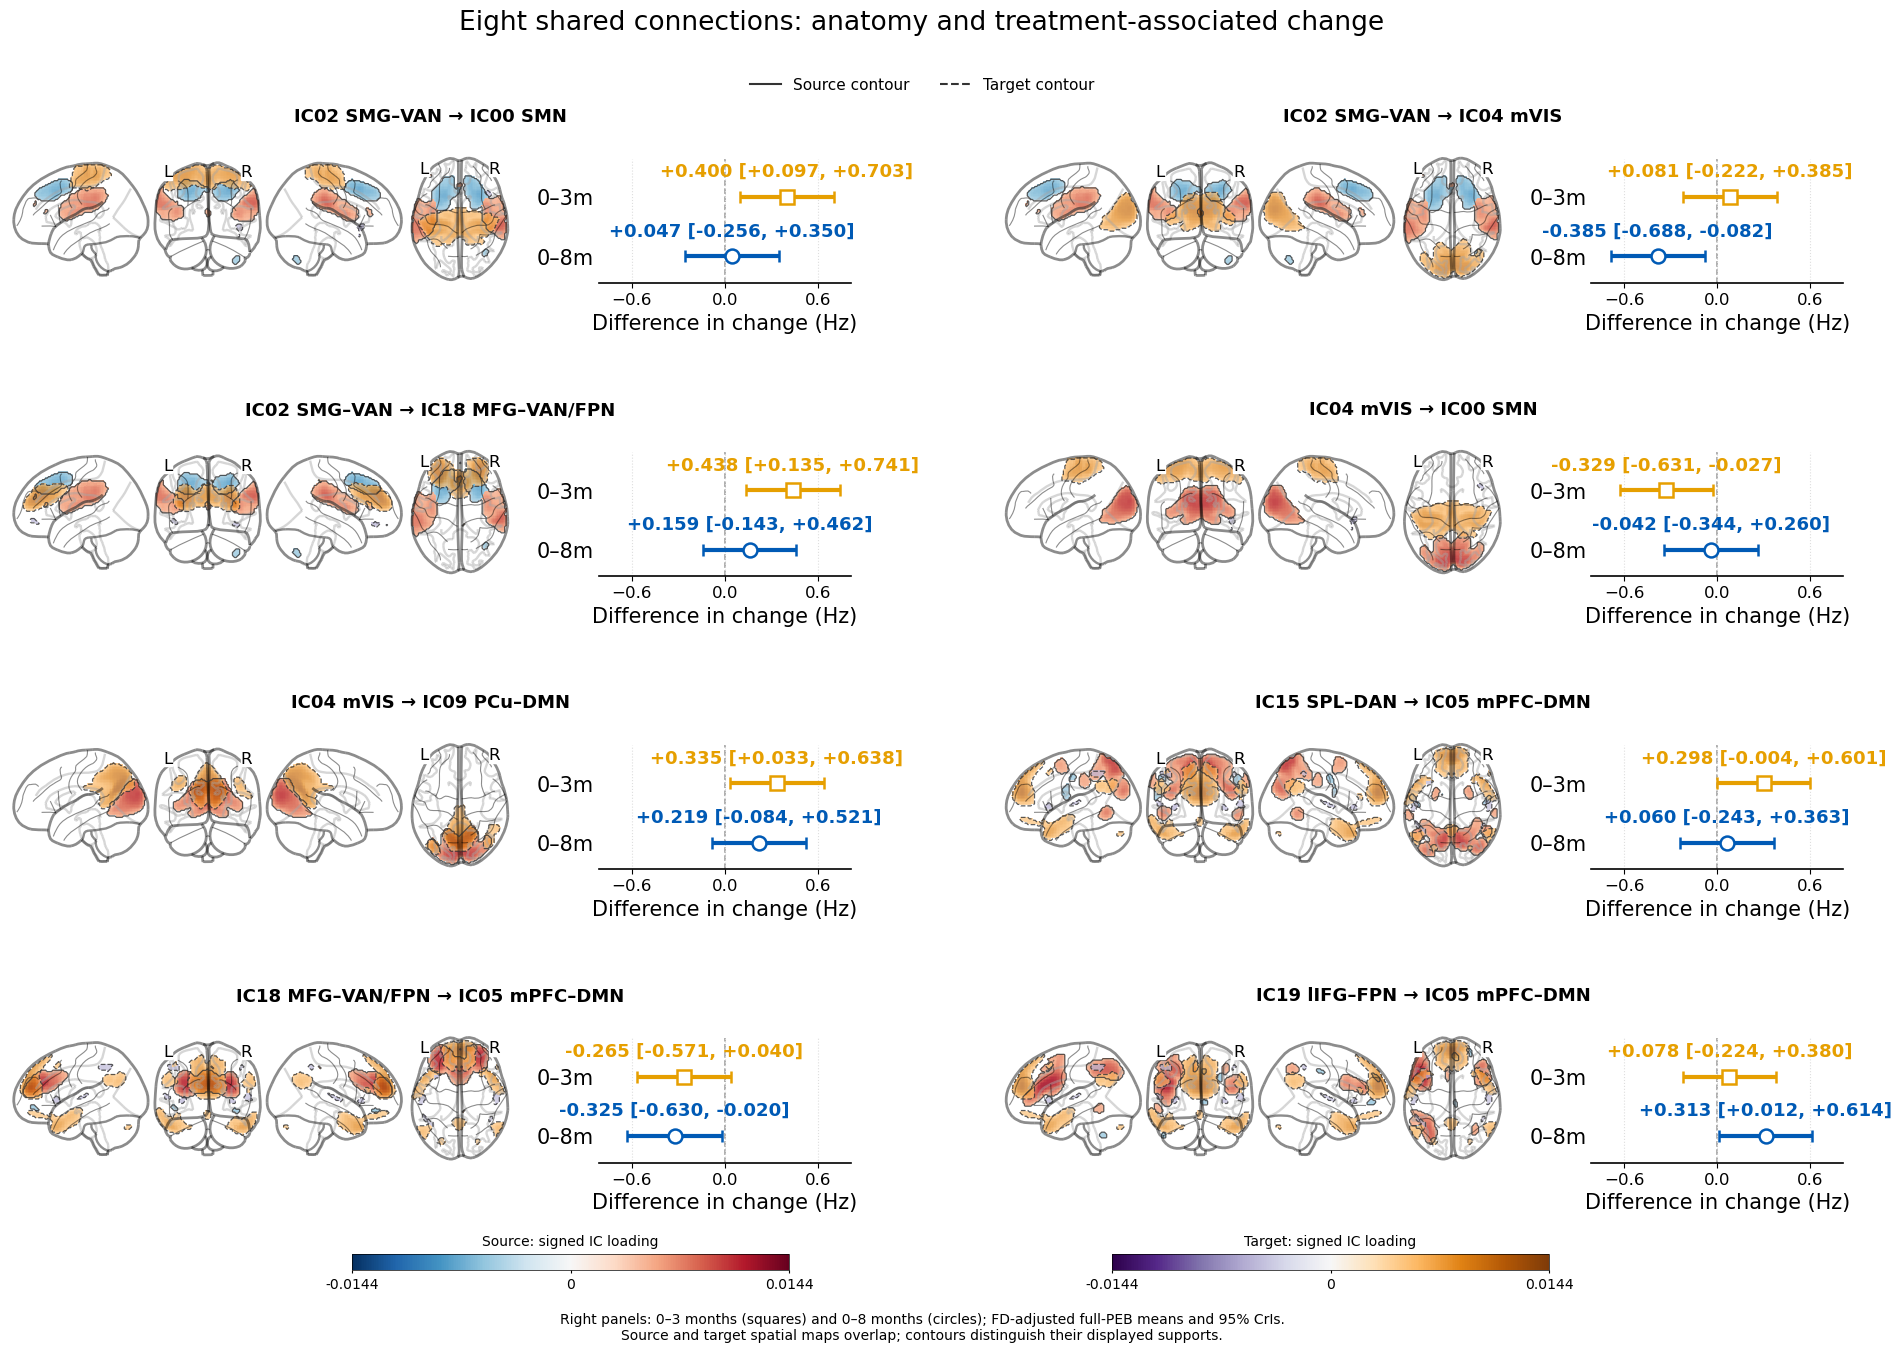

Figure 4 glass brains and effect plots saved separately in: /scratch/repo_sz_meditation/fig/Section3_PPT/Fig4_parts


In [ ]:
# Place overlaid source/target brains left and both FD-adjusted contrasts right; save eight separate EC panels.
def draw_ec_primary_panel(fig, rect, edge, title_size=13):
    x, y, width, height = rect
    fig.text(x + width/2, y + height, edge_name(edge), ha='center', va='bottom',
             fontsize=title_size, fontweight='bold')
    brain = draw_ec_overlay(fig, [x, y + 0.14*height,
                                  EC_BRAIN_FRACTION*width, 0.70*height], edge)
    right_start = EC_BRAIN_FRACTION + EC_PANEL_GAP
    ax = fig.add_axes([x + right_start*width, y + 0.14*height,
                       (1-right_start)*width, 0.68*height])
    plot_primary_contrasts(ax, edge)
    return brain

def overlay_role_legend(fig, y=0.945):
    handles = [Line2D([], [], color='0.20', linestyle=contour_styles[role],
                       linewidth=1.5, label=f'{role.capitalize()} contour')
               for role in ['source', 'target']]
    fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, y),
               frameon=False, ncol=2, fontsize=11)

fig_main = plt.figure(figsize=(19, 13.8), facecolor='white')
grid_main = fig_main.add_gridspec(4, 2, left=0.02, right=0.985, top=0.90,
                                 bottom=0.13, hspace=0.60, wspace=0.18)
main_brains = []
for index, edge in enumerate(edge_order):
    box = grid_main[index // 2, index % 2].get_position(fig_main)
    main_brains.append(draw_ec_primary_panel(fig_main, box.bounds, edge))
fig_main.suptitle('Eight shared connections: anatomy and treatment-associated change',
                  fontsize=19, y=0.984)
overlay_role_legend(fig_main)
add_brain_keys(fig_main, y=0.071, fontsize=10)
fig_main.text(0.5, 0.020,
              'Right panels: 0–3 months (squares) and 0–8 months (circles); FD-adjusted full-PEB means and 95% CrIs.\n'
              'Source and target spatial maps overlap; contours distinguish their displayed supports.',
              ha='center', fontsize=10)
save_figure(fig_main, 'Fig4_eight_EC_overlaid_brains_FD')
plt.show()

# Save each Figure 4 glass brain and its two-window effect plot separately for PPT.
# Reuse the current maps, contours and saved FD-adjusted contrasts; output transparent PNG/PDF pairs.
if SAVE_EC_PANELS:
    for index, edge in enumerate(edge_order, start=1):
        stem = f'Fig4_{index:02d}_{edge[0][:4]}_to_{edge[1][:4]}_p{EC_PERCENTILE:g}_{EC_VIEWS}'

        fig_brain = plt.figure(figsize=(8.6, 2.8), facecolor='none')
        brain = draw_signed_overlay(
            fig_brain, [0.01, 0.04, 0.98, 0.92],
            [(edge[0], 'source'), (edge[1], 'target')],
            ec_panel_maps, EC_VIEWS, transparent=True)
        save_ppt_figure(fig_brain, f'{stem}_glassbrain', 'Fig4_parts', transparent=True)
        plt.close(fig_brain)

        fig_effect, ax = plt.subplots(figsize=(4.6, 3.6), facecolor='none')
        ax.set_facecolor('none')
        plot_primary_contrasts(ax, edge)
        fig_effect.subplots_adjust(left=0.17, right=0.97, bottom=0.22, top=0.94)
        save_ppt_figure(fig_effect, f'{stem}_effects', 'Fig4_parts', transparent=True)
        plt.close(fig_effect)

    print('Figure 4 glass brains and effect plots saved separately in:', ppt_dir / 'Fig4_parts')

## 5c. Show the complete five-specification comparison for the supplement.


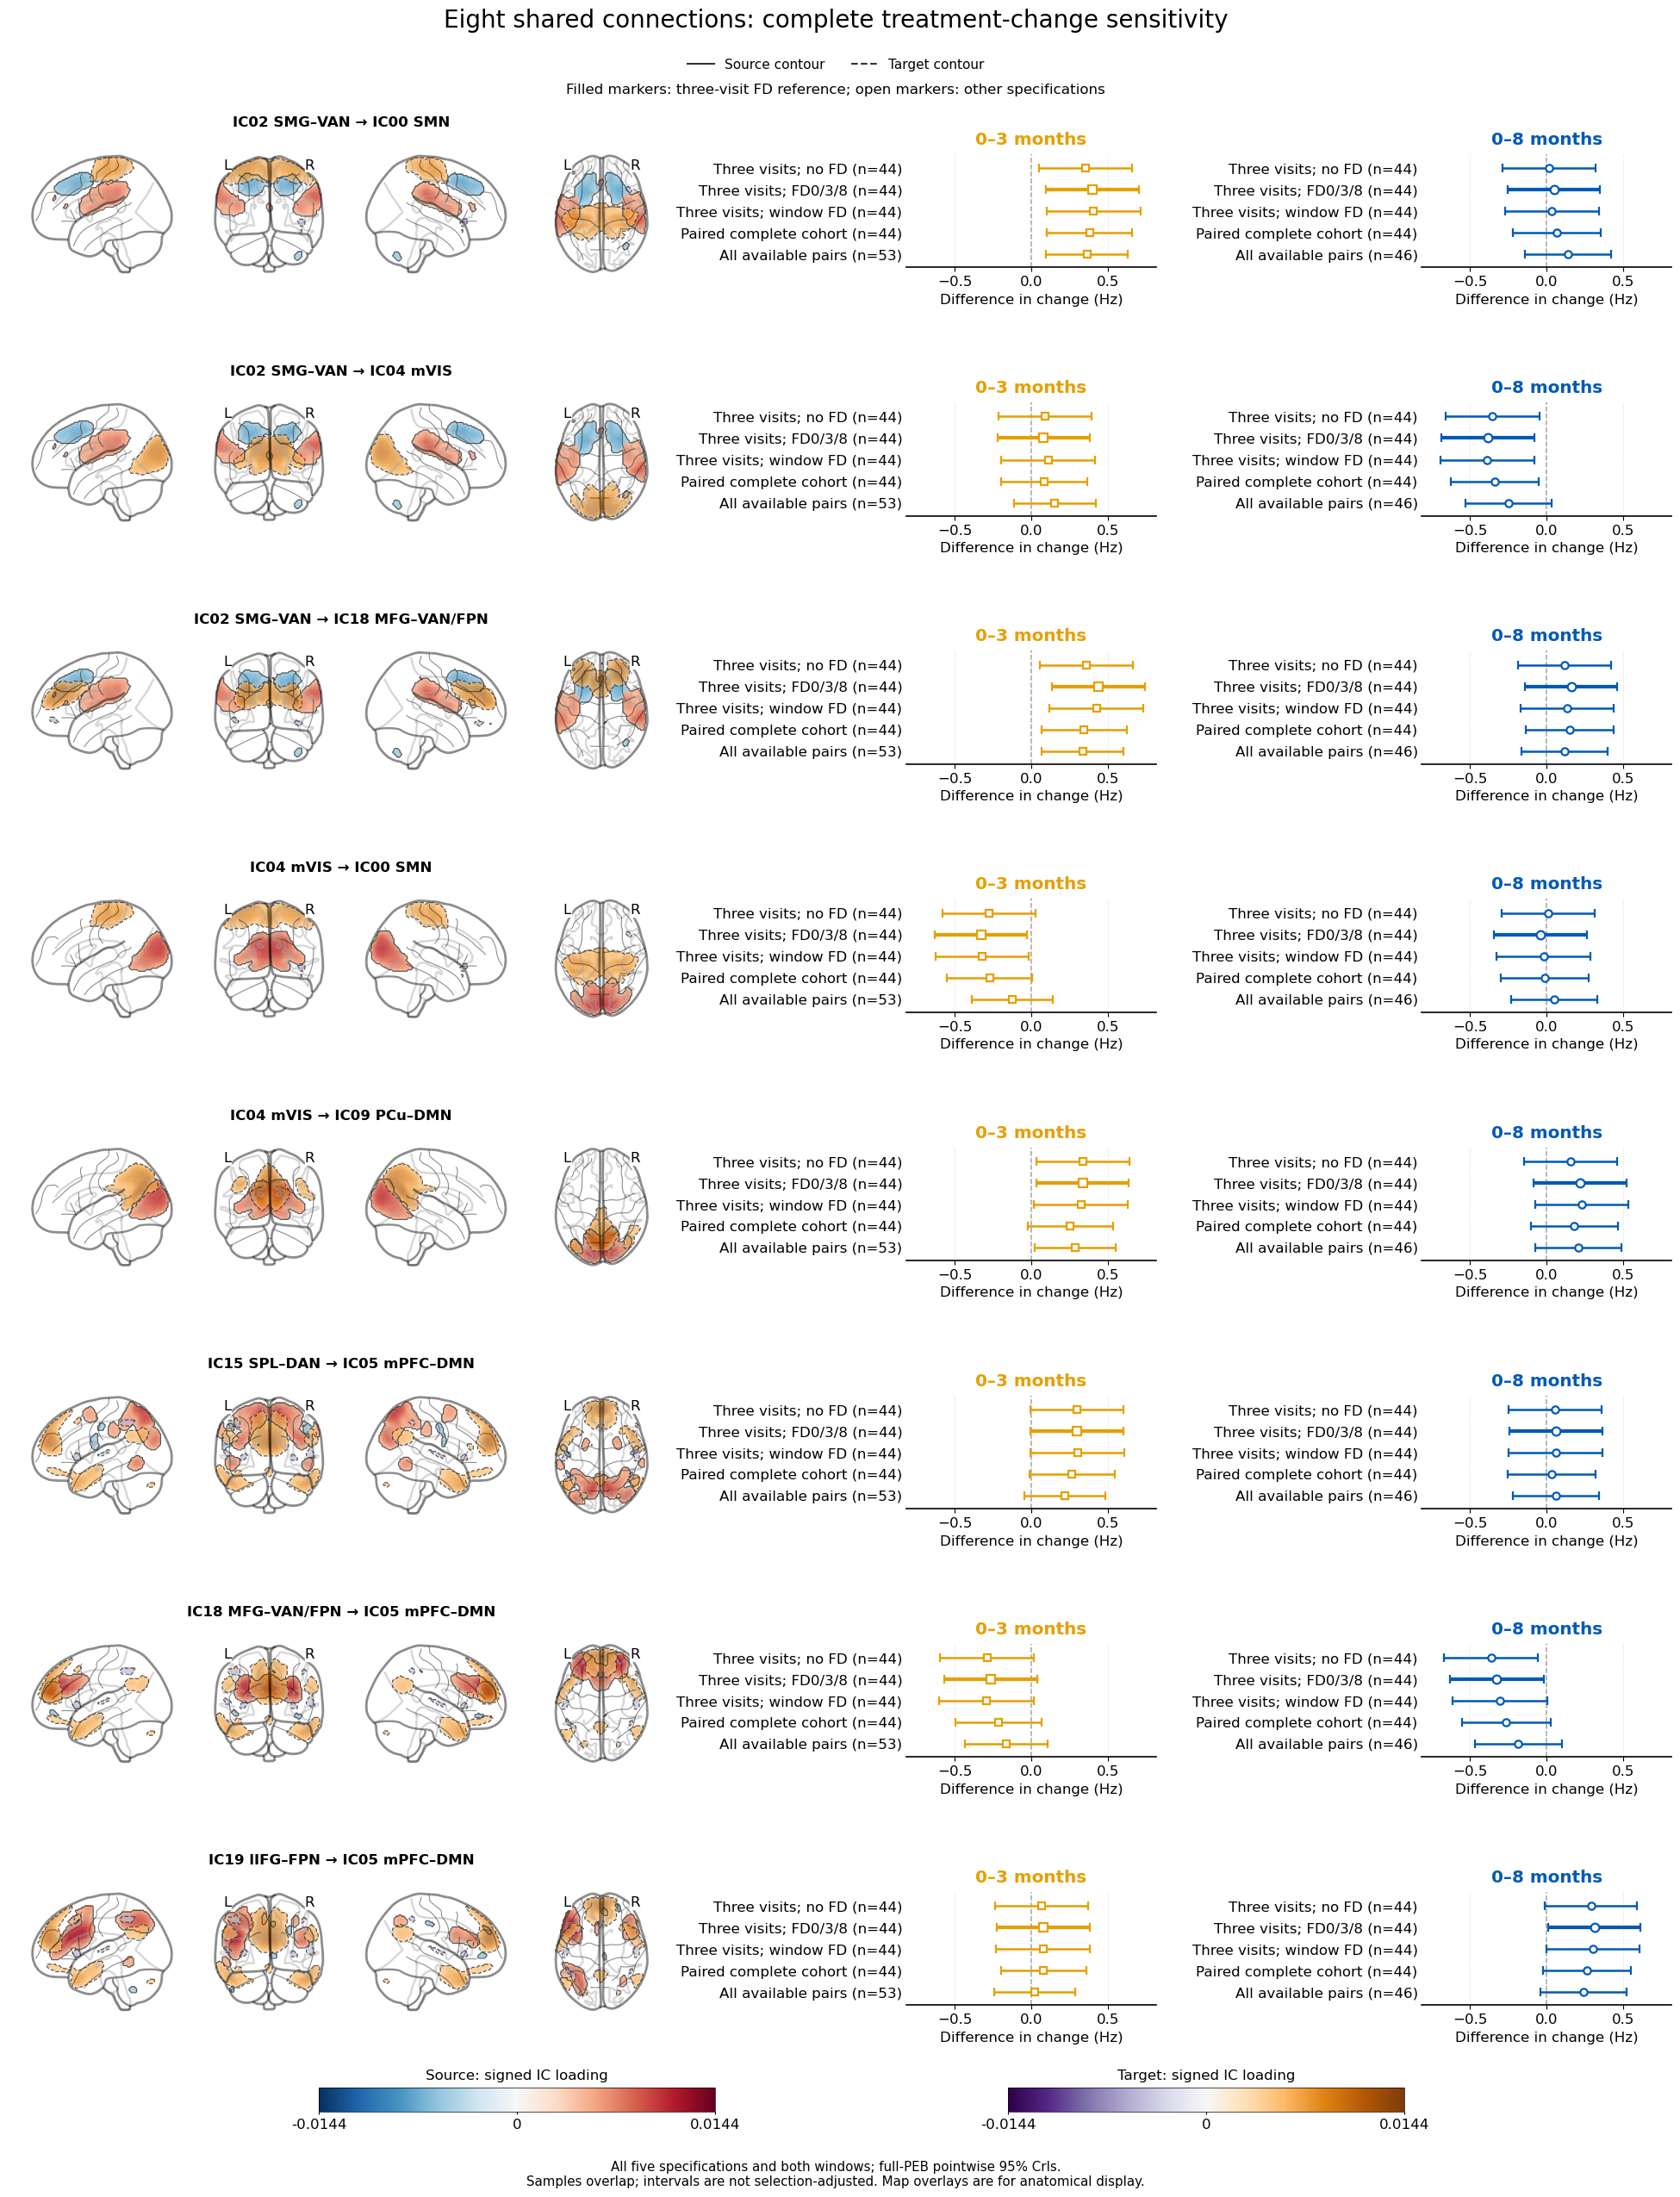

In [57]:
# Retain the full eight-row supplementary design: overlaid brain, early sensitivities, late sensitivities.
XLABEL_SIZE = 12
def draw_ec_sensitivity_panel(fig, rect, edge, title_size=12):
    x, y, width, height = rect
    # The gaps hold the full model labels, so they cannot collide with the anatomy.
    fig.text(x + 0.20*width, y + height, edge_name(edge), ha='center', va='bottom',
             fontsize=title_size, fontweight='bold')
    brain = draw_ec_overlay(fig, [x, y + 0.06*height, 0.40*width, 0.79*height], edge)
    for month, left in [(3, 0.54), (8, 0.85)]:
        ax = fig.add_axes([x + left*width, y + 0.11*height, 0.15*width, 0.73*height])
        plot_contrast_sensitivity(ax, edge, month)
        ax.set_title(f'0–{month} months', color=month_colors[month],
                     fontsize=XLABEL_SIZE*1.2, fontweight='bold', pad=8)
        ax.set_xlabel('Difference in change (Hz)', fontsize=XLABEL_SIZE)
    return brain

fig_all = plt.figure(figsize=(20, 3*len(edge_order)+2), facecolor='white')
grid_all = fig_all.add_gridspec(len(edge_order), 1, left=0.02, right=0.985,
                               top=0.93, bottom=0.085, hspace=0.60)
sensitivity_brains = []
for index, edge in enumerate(edge_order):
    box = grid_all[index, 0].get_position(fig_all)
    sensitivity_brains.append(draw_ec_sensitivity_panel(fig_all, box.bounds, edge))
fig_all.suptitle('Eight shared connections: complete treatment-change sensitivity',
                 fontsize=20, y=0.984)
overlay_role_legend(fig_all, y=0.967)
fig_all.text(0.5, 0.946, 'Filled markers: three-visit FD reference; open markers: other specifications',
             ha='center', fontsize=12)
add_brain_keys(fig_all, y=0.045, fontsize=XLABEL_SIZE)
fig_all.text(0.5, 0.012, 'All five specifications and both windows; full-PEB pointwise 95% CrIs.\n'
             'Samples overlap; intervals are not selection-adjusted. Map overlays are for anatomical display.',
             ha='center', fontsize=XLABEL_SIZE*0.9)
save_figure(fig_all, 'SM_eight_EC_five_specifications_overlay')
plt.show()

if SAVE_EC_PANELS:
    for index, edge in enumerate(edge_order, start=1):
        fig = plt.figure(figsize=(20, 3.5), facecolor='white')
        draw_ec_sensitivity_panel(fig, [0.015, 0.13, 0.97, 0.70], edge, title_size=14)
        stem = f'SM_{index:02d}_{edge[0][:4]}_to_{edge[1][:4]}_p{EC_PERCENTILE:g}_sensitivity'
        save_ppt_figure(fig, stem, 'Sensitivity_panels')
        plt.close(fig)

## 6. Show all eight observed trajectories and the additional FD candidates for the supplement.


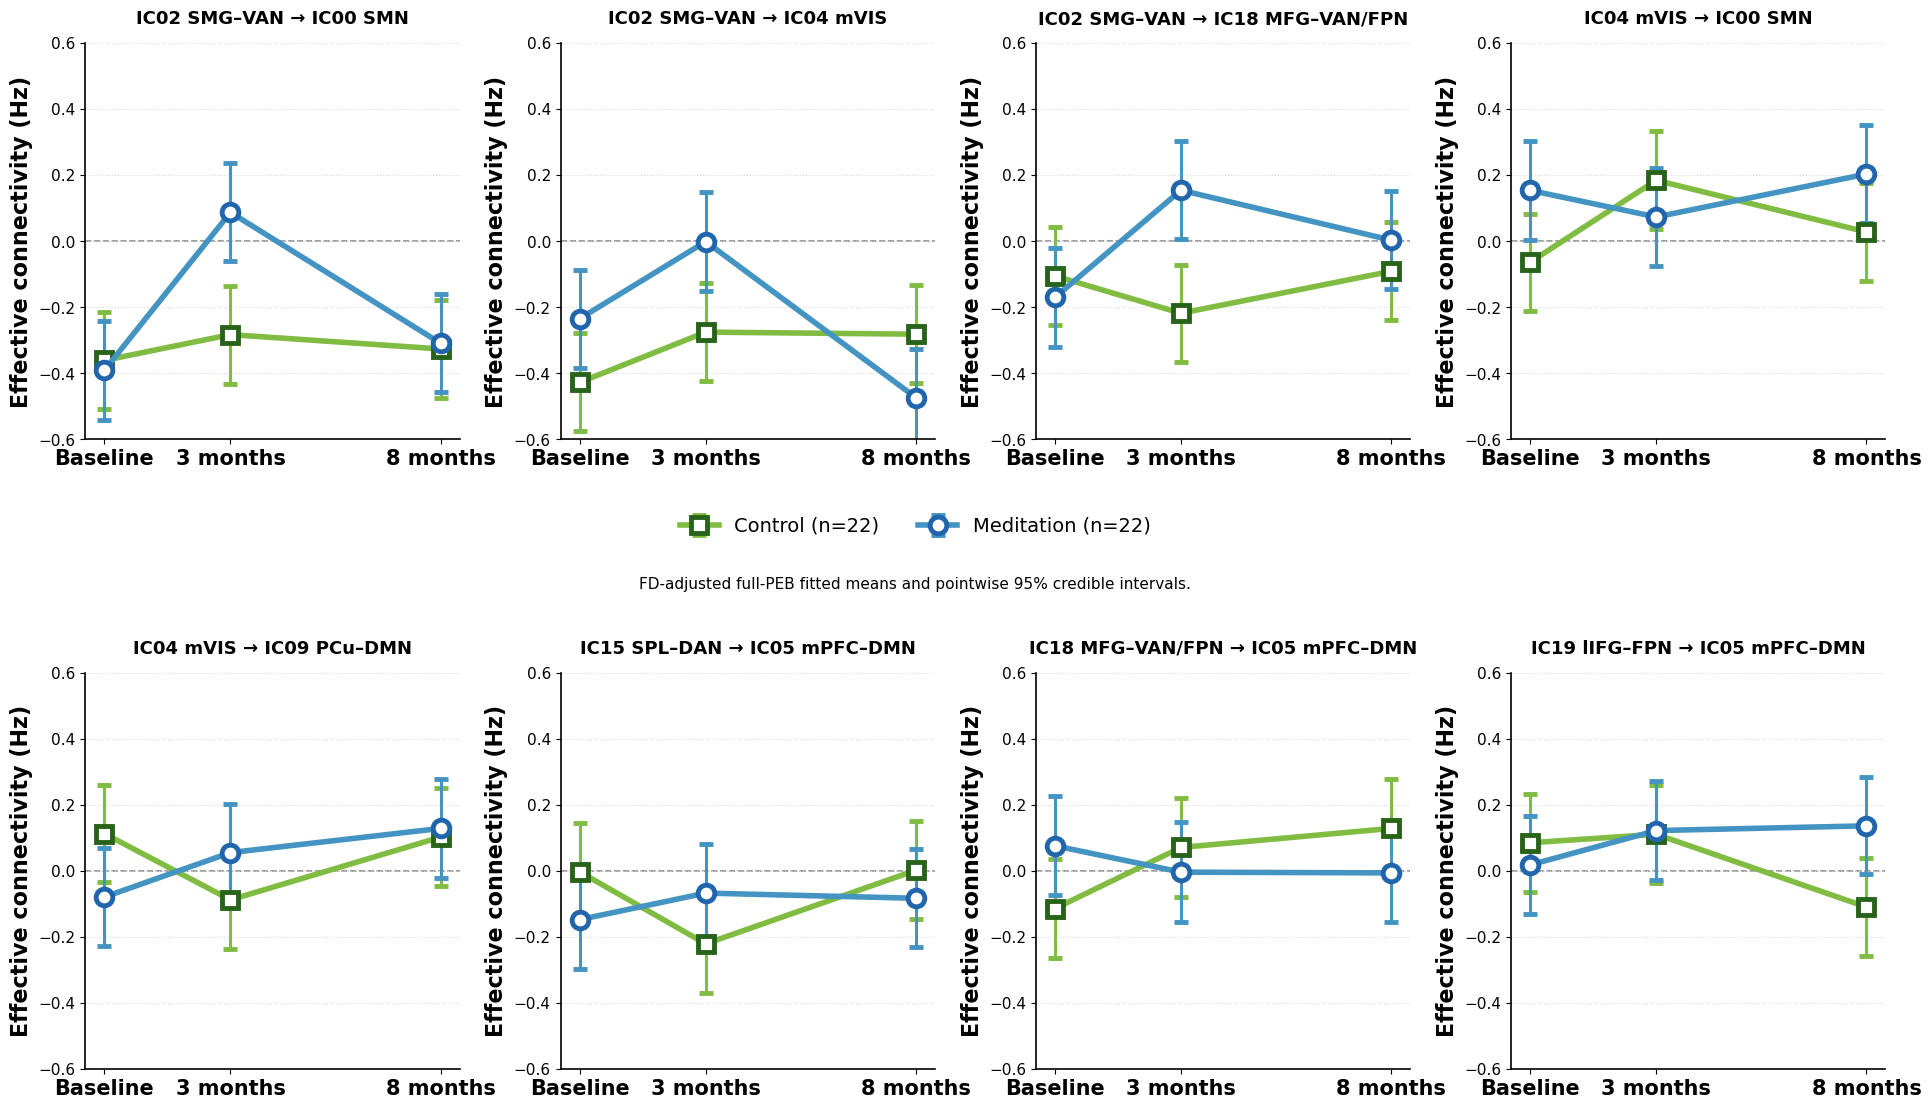

In [19]:
# Show all eight saved FD-adjusted fitted trajectories with the same style and pointwise intervals.
fig_trajectories, axes = plt.subplots(2, 4, figsize=(20, 12),
                                     facecolor='white', squeeze=False)
for ax, edge in zip(axes.flat, edge_order):
    plot_trajectory(ax, edge)
    ax.set_ylim(-0.6, 0.6)
    #ax.set_y(-0.6, 0.6)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig_trajectories.legend(handles, labels, loc='upper center', ncol=2,
                        bbox_to_anchor=(0.5, 0.53), frameon=False, fontsize=14)
#fig_trajectories.suptitle(f'Trajectories of eight shared connections | N = {N_discovery}',
#                         y=0.991, fontsize=19)
fig_trajectories.text(0.5, 0.455, 'FD-adjusted full-PEB fitted means and pointwise 95% credible intervals.', ha='center', fontsize=11)
fig_trajectories.subplots_adjust(left=0.085, right=0.985, bottom=0.055,
                                 top=0.91, hspace=0.59, wspace=0.27)
save_figure(fig_trajectories, 'SM_eight_EC_FD_fitted_trajectories')
plt.show()

## 7. Display the supplementary treatment-coefficient table.


In [17]:
# Format saved sensitivity contrasts and treatment coefficients; export exactly two supplementary CSVs.
all_report_edges = edge_order + [
    tuple(edge) for edge in edge_dictionary[['Source_Node', 'Target_Node']].to_numpy()
    if tuple(edge) not in edge_order]
edge_positions = {edge: index for index, edge in enumerate(all_report_edges)}

summary_rows = []
for edge in all_report_edges:
    for month in [3, 8]:
        row = evidence.loc[(*edge, month)]
        record = {'Edge': edge_name(edge), 'Source_Node': edge[0], 'Target_Node': edge[1],
                  'Reporting_set': 'Shared eight' if edge in edge_order else 'Additional FD candidate',
                  'Focal_edge': edge in focal_edges, 'Window_months': f'0–{month}',
                  'Contrast': 'Meditation minus control difference in change', 'Unit': 'Hz',
                  'NoFD_selected_terms': row['NoFD_selected_terms'],
                  'FD_selected_terms': row['FD_selected_terms'],
                  'Interval': 'Full-PEB pointwise 95% CrI; not BMA or selection-adjusted'}
        for prefix, label in specifications:
            mean, low, high = effect_values(edge, month, prefix)
            saved = change_index.loc[(*edge, month, next(
                model for model, saved_prefix in model_prefixes.items() if saved_prefix == prefix))]
            record[f'{prefix}_mean_95CrI_Hz'] = f'{mean:+.3f} [{low:+.3f}, {high:+.3f}]'
            record[f'{prefix}_N_control_meditation'] = f'{int(saved["N"])} ({int(saved["Control_N"])}/{int(saved["Meditation_N"])})'
            for field, value in [('mean_Hz', mean), ('CrI95_low_Hz', low), ('CrI95_high_Hz', high)]:
                record[f'{prefix}_{field}'] = value
            record[f'{prefix}_Motion_covariates'] = saved['Motion_covariates']
        fd_mean = effect_values(edge, month)[0]
        matching = sum((effect_values(edge, month, prefix)[1] > 0 if fd_mean > 0 else
                        effect_values(edge, month, prefix)[2] < 0 if fd_mean < 0 else False)
                       for prefix, _ in specifications)
        record['Same_direction_nonzero_CrIs_of_5'] = matching
        record['Interpretation'] = 'Descriptive within-study consistency; overlapping samples; pointwise CrIs'
        summary_rows.append(record)
supp_sensitivity = pd.DataFrame(summary_rows)
sensitivity_display_columns = ['Edge', 'Reporting_set', 'Window_months'] + [
    f'{prefix}_mean_95CrI_Hz' for prefix, _ in specifications]
supp_sensitivity = supp_sensitivity[sensitivity_display_columns + [
    column for column in supp_sensitivity if column not in sensitivity_display_columns]]

report_coefficients = coefficients.loc[
    saved_flag(coefficients['Selected_No_FD']) | saved_flag(coefficients['Selected_FD_adjusted'])
].copy()
report_coefficients['Edge'] = [edge_name(edge) for edge in
    report_coefficients[['Source_Node', 'Target_Node']].itertuples(index=False, name=None)]
report_coefficients['Reporting_set'] = [
    'Shared eight' if edge in edge_order else 'Additional FD candidate' for edge in
    report_coefficients[['Source_Node', 'Target_Node']].itertuples(index=False, name=None)]
report_coefficients['FullPEB_mean_95CrI'] = [
    f'{mean:+.4f} [{low:+.4f}, {high:+.4f}]' for mean, low, high in
    report_coefficients[['FullPEB_mean', 'FullPEB_CrI95_low', 'FullPEB_CrI95_high']].to_numpy()]
report_coefficients['BMA_Pp_display'] = report_coefficients['BMA_Pp'].map(
    lambda value: '>0.999' if value > 0.999 else '<0.001' if value < 0.001 else f'{value:.3f}')
report_coefficients['Term_selected_in_this_model'] = report_coefficients['BMA_Pp'].gt(
    report_coefficients['Pp_threshold'])
report_coefficients['BMA_Pp_interpretation'] = 'BMA inclusion support; not the probability of the full-PEB CrI'
report_coefficients['_edge_order'] = [edge_positions[edge] for edge in
    report_coefficients[['Source_Node', 'Target_Node']].itertuples(index=False, name=None)]
report_coefficients = report_coefficients.sort_values(['_edge_order', 'Model', 'Term'])
coefficient_columns = [
    'Edge', 'Reporting_set', 'Model', 'Term', 'Unit', 'FullPEB_mean_95CrI',
    'BMA_MeditationMinusControl', 'BMA_Pp_display', 'Term_selected_in_this_model',
    'Source_Node', 'Target_Node', 'FullPEB_mean', 'FullPEB_CrI95_low', 'FullPEB_CrI95_high',
    'BMA_Pp', 'Pp_threshold', 'Selected_No_FD', 'Selected_FD_adjusted', 'Selected_both',
    'N', 'Control_N', 'Meditation_N', 'Group_scale_factor', 'Interval', 'BMA_Pp_interpretation',
]
supp_coefficients = report_coefficients[coefficient_columns].copy()
display(supp_sensitivity[sensitivity_display_columns])
display(supp_coefficients.iloc[:, :9])
if save_tables:
    supp_sensitivity.to_csv(peb_path / 'Supplementary_EC_sensitivity_summary.csv',
                            index=False, encoding='utf-8-sig')
    supp_coefficients.to_csv(peb_path / 'Supplementary_PEB_treatment_coefficients.csv',
                             index=False, encoding='utf-8-sig')
    print('Saved the two supplementary tables in:', peb_path)

,Edge,Reporting_set,Window_months,NoFD_3visit_mean_95CrI_Hz,FD_3visit_mean_95CrI_Hz,WindowFD_3visit_mean_95CrI_Hz,Paired44_mean_95CrI_Hz,All_pairs_mean_95CrI_Hz
0,IC02 SMG–VAN → IC00 SMN,Shared eight,0–3,"+0.354 [+0.050, +0.658]","+0.400 [+0.097, +0.703]","+0.407 [+0.100, +0.715]","+0.380 [+0.100, +0.661]","+0.364 [+0.097, +0.630]"
1,IC02 SMG–VAN → IC00 SMN,Shared eight,0–8,"+0.015 [-0.290, +0.319]","+0.047 [-0.256, +0.350]","+0.034 [-0.272, +0.340]","+0.066 [-0.221, +0.353]","+0.138 [-0.144, +0.420]"
2,IC02 SMG–VAN → IC04 mVIS,Shared eight,0–3,"+0.090 [-0.214, +0.395]","+0.081 [-0.222, +0.385]","+0.110 [-0.197, +0.418]","+0.086 [-0.194, +0.367]","+0.153 [-0.113, +0.420]"
3,IC02 SMG–VAN → IC04 mVIS,Shared eight,0–8,"-0.353 [-0.658, -0.049]","-0.385 [-0.688, -0.082]","-0.388 [-0.694, -0.082]","-0.337 [-0.624, -0.050]","-0.249 [-0.531, +0.034]"
4,IC02 SMG–VAN → IC18 MFG–VAN/FPN,Shared eight,0–3,"+0.363 [+0.059, +0.667]","+0.438 [+0.135, +0.741]","+0.425 [+0.119, +0.732]","+0.345 [+0.066, +0.625]","+0.336 [+0.070, +0.602]"
5,IC02 SMG–VAN → IC18 MFG–VAN/FPN,Shared eight,0–8,"+0.117 [-0.187, +0.420]","+0.159 [-0.143, +0.462]","+0.133 [-0.173, +0.438]","+0.148 [-0.138, +0.435]","+0.116 [-0.165, +0.398]"
6,IC04 mVIS → IC00 SMN,Shared eight,0–3,"-0.273 [-0.577, +0.030]","-0.329 [-0.631, -0.027]","-0.321 [-0.627, -0.015]","-0.271 [-0.550, +0.008]","-0.124 [-0.389, +0.142]"
7,IC04 mVIS → IC00 SMN,Shared eight,0–8,"+0.008 [-0.296, +0.311]","-0.042 [-0.344, +0.260]","-0.020 [-0.325, +0.286]","-0.013 [-0.299, +0.274]","+0.049 [-0.232, +0.330]"
8,IC04 mVIS → IC09 PCu–DMN,Shared eight,0–3,"+0.339 [+0.035, +0.643]","+0.335 [+0.033, +0.638]","+0.324 [+0.017, +0.630]","+0.256 [-0.024, +0.535]","+0.288 [+0.022, +0.554]"
9,IC04 mVIS → IC09 PCu–DMN,Shared eight,0–8,"+0.157 [-0.147, +0.460]","+0.219 [-0.084, +0.521]","+0.230 [-0.076, +0.535]","+0.181 [-0.105, +0.467]","+0.208 [-0.073, +0.489]"


,Edge,Reporting_set,Model,Term,Unit,FullPEB_mean_95CrI,BMA_MeditationMinusControl,BMA_Pp_display,Term_selected_in_this_model
152,IC02 SMG–VAN → IC00 SMN,Shared eight,FD_adjusted,Group_x_Linear,Hz/month,"-0.0019 [-0.0394, +0.0356]",3.765281e-07,<0.001,False
224,IC02 SMG–VAN → IC00 SMN,Shared eight,FD_adjusted,Group_x_Quadratic,Hz/month^2,"-0.0255 [-0.0432, -0.0078]",-2.548276e-02,>0.999,True
8,IC02 SMG–VAN → IC00 SMN,Shared eight,No_FD,Group_x_Linear,Hz/month,"-0.0053 [-0.0430, +0.0324]",-4.383519e-07,<0.001,False
80,IC02 SMG–VAN → IC00 SMN,Shared eight,No_FD,Group_x_Quadratic,Hz/month^2,"-0.0232 [-0.0410, -0.0055]",-2.334175e-02,>0.999,True
153,IC02 SMG–VAN → IC04 mVIS,Shared eight,FD_adjusted,Group_x_Linear,Hz/month,"-0.0527 [-0.0903, -0.0152]",-5.175649e-02,>0.999,True
225,IC02 SMG–VAN → IC04 mVIS,Shared eight,FD_adjusted,Group_x_Quadratic,Hz/month^2,"-0.0151 [-0.0327, +0.0026]",-5.612105e-06,<0.001,False
9,IC02 SMG–VAN → IC04 mVIS,Shared eight,No_FD,Group_x_Linear,Hz/month,"-0.0487 [-0.0864, -0.0110]",-4.692086e-02,>0.999,True
81,IC02 SMG–VAN → IC04 mVIS,Shared eight,No_FD,Group_x_Quadratic,Hz/month^2,"-0.0149 [-0.0326, +0.0029]",-8.806461e-06,<0.001,False
158,IC02 SMG–VAN → IC18 MFG–VAN/FPN,Shared eight,FD_adjusted,Group_x_Linear,Hz/month,"+0.0122 [-0.0252, +0.0496]",2.081465e-06,<0.001,False
230,IC02 SMG–VAN → IC18 MFG–VAN/FPN,Shared eight,FD_adjusted,Group_x_Quadratic,Hz/month^2,"-0.0252 [-0.0429, -0.0076]",-2.450728e-02,>0.999,True


Saved the two supplementary tables in: /scratch/repo_sz_meditation/data/dcm/PEB_section3


## 8. Optional: display the focal full-PEB fitted trajectories.


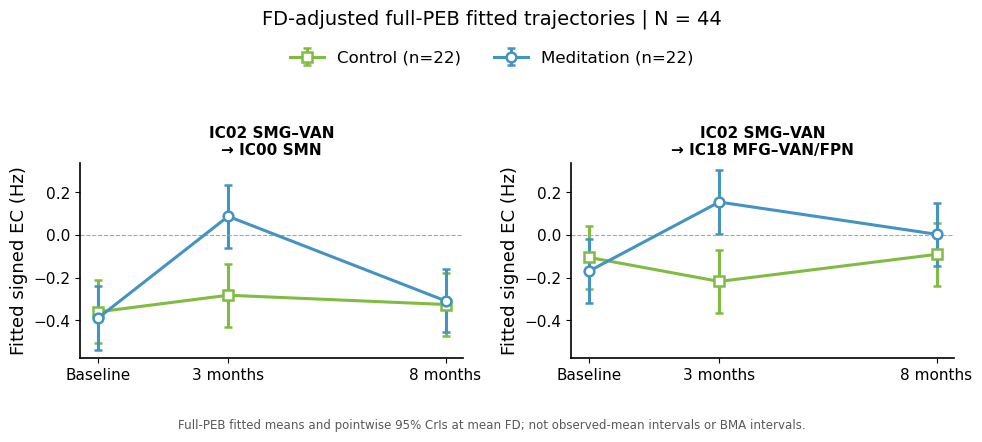

In [18]:
# 8. Optional: display the focal full-PEB fitted trajectories.
# Combine all fitted time terms at mean FD; 95% intervals belong to fitted full-PEB means only.
fig_fitted, axes = plt.subplots(1, 2, figsize=(10, 4.3), facecolor='white')
for ax, edge in zip(axes, focal_edges):
    for group, color in ec_colors.items():
        part = fitted_means.loc[fitted_means['Model'].eq('FD_adjusted')
                                & fitted_means['Source_Node'].eq(edge[0])
                                & fitted_means['Target_Node'].eq(edge[1])
                                & fitted_means['Group'].eq(group)].sort_values('End_month')
        mean = part['FullPEB_mean_Hz'].to_numpy()
        error = np.vstack([mean-part['FullPEB_CrI95_low_Hz'].to_numpy(),
                           part['FullPEB_CrI95_high_Hz'].to_numpy()-mean])
        ax.errorbar(part['End_month'], mean, yerr=error, color=color,
                    marker=ec_markers[group], linewidth=2.2, markersize=7,
                    markerfacecolor='white', markeredgewidth=1.8, capsize=3,
                    label=f'{group.capitalize()} (n={arm_counts[group]})')
    ax.set_title(edge_name(edge).replace(' → ', '\n→ '), fontsize=11, fontweight='bold')
    ax.set_xticks(visits)
    ax.set_xticklabels(['Baseline', '3 months', '8 months'])
    ax.set_ylabel('Fitted signed EC (Hz)')
    ax.axhline(0, color='0.65', linestyle='--', linewidth=0.8)
    sns.despine(ax=ax)
ylim = (min(ax.get_ylim()[0] for ax in axes), max(ax.get_ylim()[1] for ax in axes))
for ax in axes:
    ax.set_ylim(ylim)
handles, legend_labels = axes[0].get_legend_handles_labels()
fig_fitted.suptitle(f'FD-adjusted full-PEB fitted trajectories | N = {N_discovery}', y=0.99, fontsize=14)
fig_fitted.legend(handles, legend_labels, loc='upper center', bbox_to_anchor=(0.5, 0.93),
                  ncol=2, frameon=False)
fig_fitted.text(0.5, 0.015,
                'Full-PEB fitted means and pointwise 95% CrIs at mean FD; not observed-mean intervals or BMA intervals.',
                ha='center', fontsize=8.5, color='0.35')
fig_fitted.tight_layout(rect=[0, 0.08, 1, 0.85])
save_figure(fig_fitted, 'SM_focal_EC_fullPEB_fitted_trajectories')
plt.show()